In [1]:
%% MIT 18.03 Lecture 2: Numerical Integration Solvers & Error Convergence
% Description: Implements Fixed-Step RK1 (Forward Euler), RK2 (Heun), and RK4.
%              Analyzes solution convergence on the lecture nonlinear benchmark
%              (y' = y^2 - x) and verifies global error scaling on y' = y.
%
% % MBD Concept Mapping: Matches Simulink fixed-step solvers (ode1, ode2, ode4).
%                      Demonstrates the trade-off between derivative evaluations
%                      (execution budget in HIL/ECU) and numerical stability/accuracy.


clear; clc; close all;


%% =========================================================================
%% Part 1: Lecture Benchmark y' = y^2 - x, y(0) = -1 (Funnel & Overshoot)
%% =========================================================================
f_nonlin = @(x, y) y^2 - x;
x0 = 0; y0 = -1; x_end = 1.0;


% Accurate benchmark solution via high-precision adaptive solver (Simulink ode45)
opts_benchmark = odeset('RelTol', 1e-11, 'AbsTol', 1e-13);
[x_ref, y_ref] = ode45(f_nonlin, [x0, x_end], y0, opts_benchmark);
y_true_1 = y_ref(end);


% Step sizes investigated in Lecture 2
h_list = [1.0, 0.5, 0.25, 0.125];
colors = [0.85 0.33 0.10; 0.93 0.69 0.13; 0.00 0.45 0.74; 0.47 0.67 0.19];


figure('Color', [1 1 1], 'Position', [100, 100, 1100, 480]);


% Subplot 1: Trajectory Tracking and Overshoot Analysis
subplot(1, 2, 1);
hold on; grid on; box on;
plot(x_ref, y_ref, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Reference (ode45)');


fprintf('=== Benchmark y'' = y^2 - x, y(0) = -1 ===\n');

=== Benchmark y' = y^2 - x, y(0) = -1 ===

In [2]:
fprintf('Reference y(1.0) = %.6f\n', y_true_1);

Reference y(1.0) = -0.833383

In [3]:


for i = 1:length(h_list)
    h = h_list(i);
    [x_eul, y_eul] = solver_euler(f_nonlin, x0, y0, x_end, h);
    plot(x_eul, y_eul, 's--', 'Color', colors(i, :), 'LineWidth', 1.3, ...
         'MarkerSize', 5, 'DisplayName', sprintf('Euler h = %.3f (y(1)=%.3f)', h, y_eul(end)));
    fprintf('Euler h = %0.3f -> Estimated y(1) = %8.4f | Error = %8.4f\n', ...
            h, y_eul(end), abs(y_eul(end) - y_true_1));
end

Euler h = 1.000 -> Estimated y(1) =   0.0000 | Error =   0.8334
Euler h = 0.500 -> Estimated y(1) =  -0.6250 | Error =   0.2084
Euler h = 0.250 -> Estimated y(1) =  -0.7545 | Error =   0.0788
Euler h = 0.125 -> Estimated y(1) =  -0.7977 | Error =   0.0357


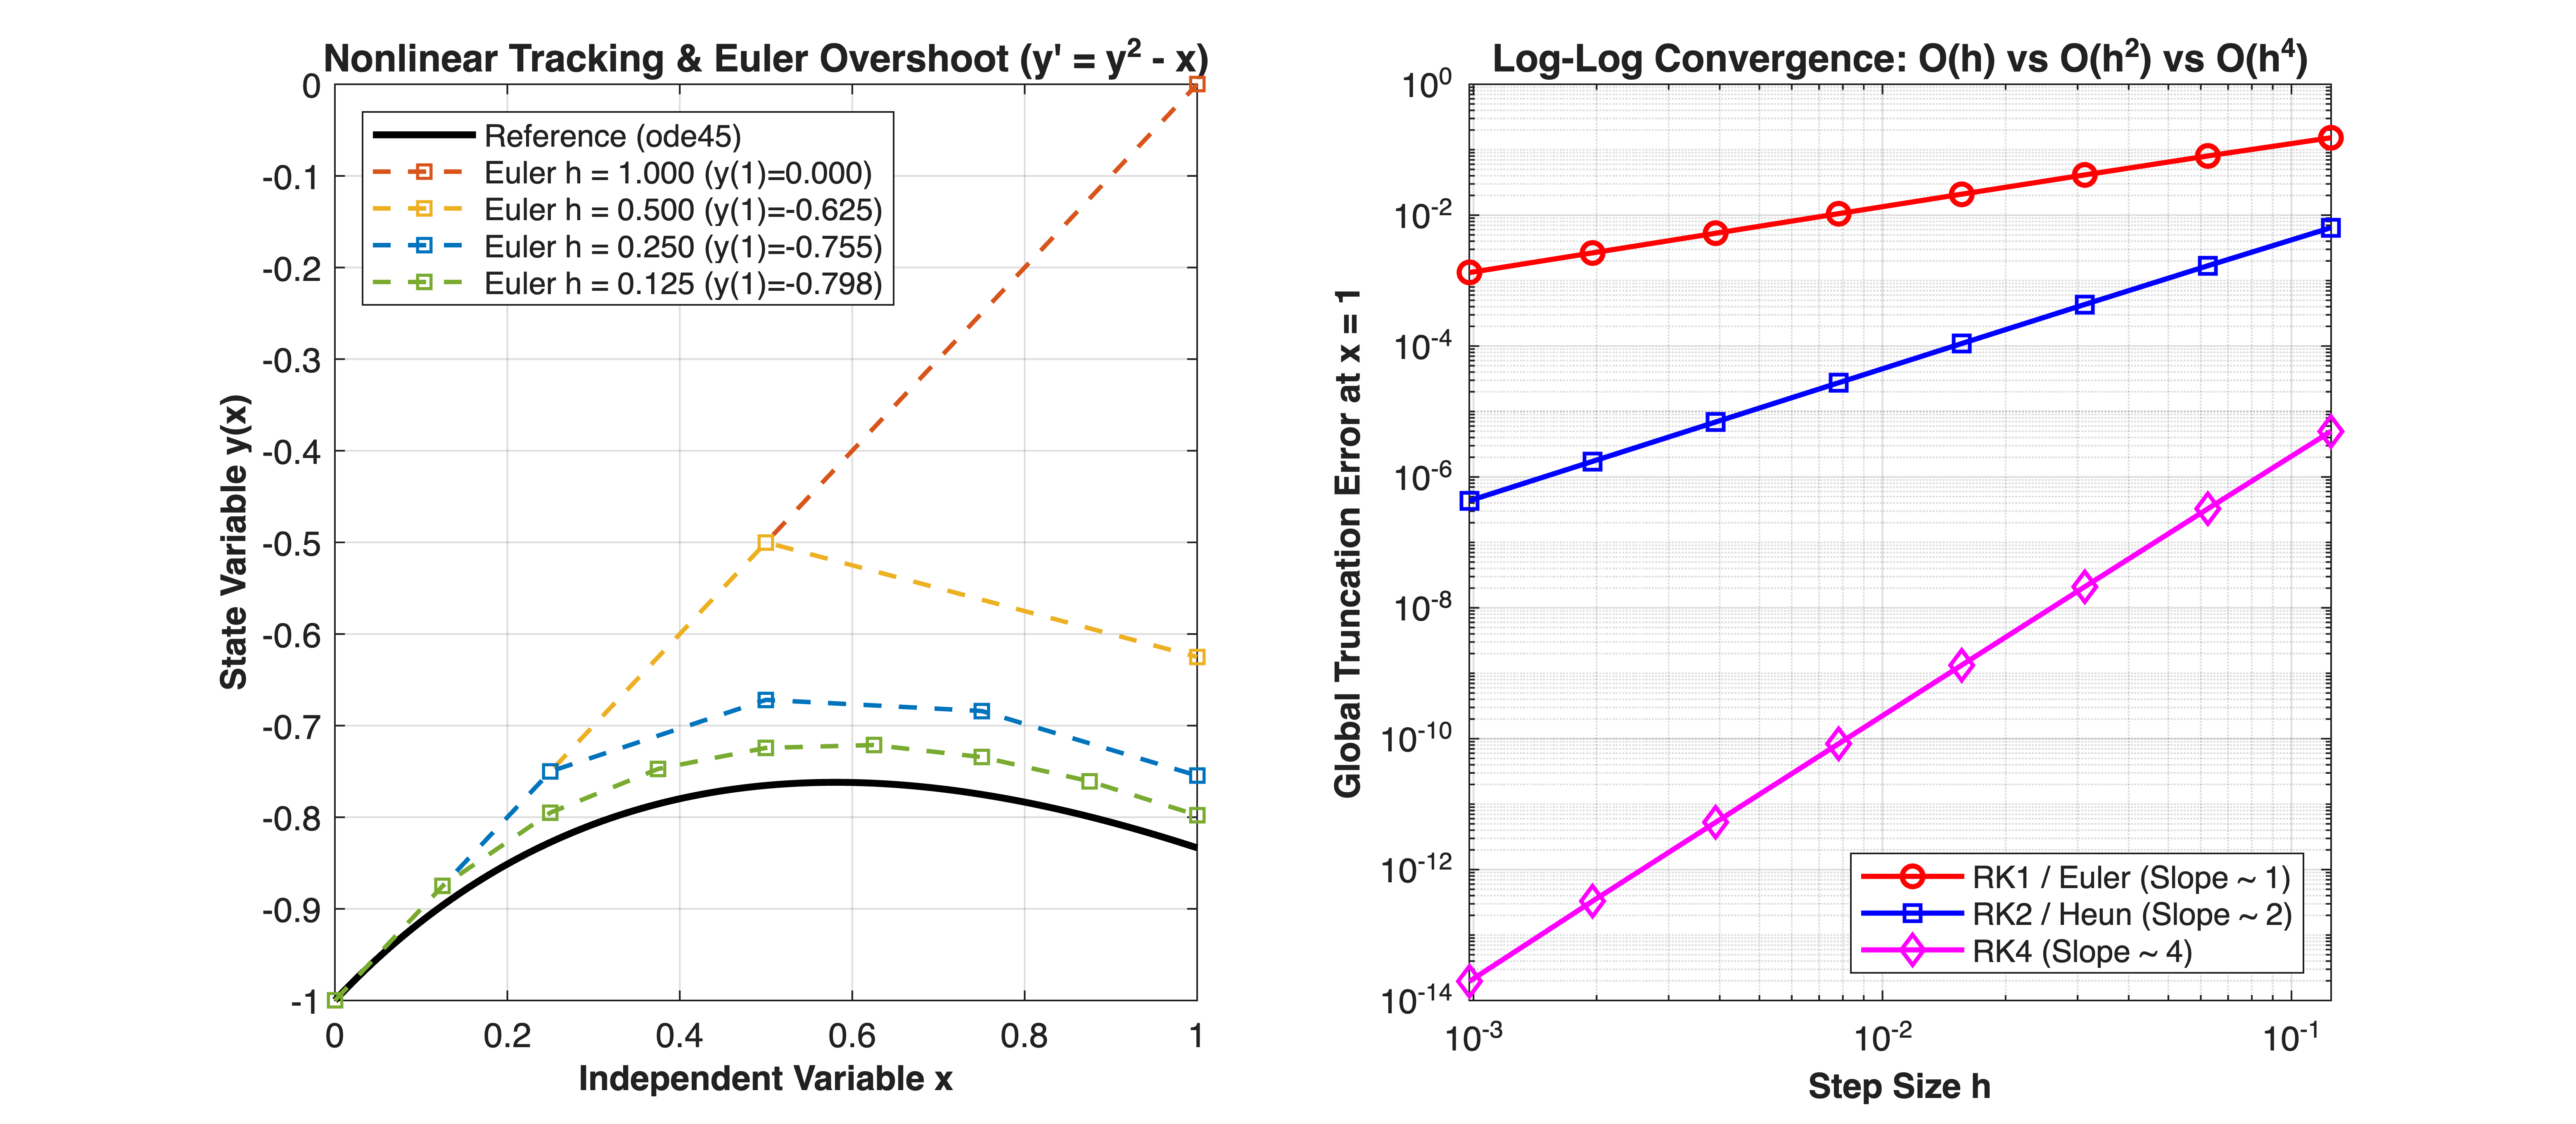

In [4]:


xlabel('Independent Variable x', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Variable y(x)', 'FontSize', 10, 'FontWeight', 'bold');
title('Nonlinear Tracking & Euler Overshoot (y'' = y^2 - x)', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 9);
xlim([x0, x_end]);


%% =========================================================================
%% Part 2: Convergence Rate Order Verification (y' = y, y(0) = 1)
%% =========================================================================
f_lin = @(x, y) y;
x0_lin = 0; y0_lin = 1; x_end_lin = 1.0;
y_exact_lin = exp(1.0); % Analytic value of e


% Sweep step sizes across decades
h_sweep = 2.^(-3:-1:-10); % From h = 1/8 down to h = 1/1024
err_rk1 = zeros(size(h_sweep));
err_rk2 = zeros(size(h_sweep));
err_rk4 = zeros(size(h_sweep));


for k = 1:length(h_sweep)
    h_curr = h_sweep(k);

    % RK1 (Euler)
    [~, y_sim1] = solver_euler(f_lin, x0_lin, y0_lin, x_end_lin, h_curr);
    err_rk1(k) = abs(y_sim1(end) - y_exact_lin);

    % RK2 (Heun)
    [~, y_sim2] = solver_heun(f_lin, x0_lin, y0_lin, x_end_lin, h_curr);
    err_rk2(k) = abs(y_sim2(end) - y_exact_lin);

    % RK4 (Classical Runge-Kutta)
    [~, y_sim4] = solver_rk4(f_lin, x0_lin, y0_lin, x_end_lin, h_curr);
    err_rk4(k) = abs(y_sim4(end) - y_exact_lin);
end


% Subplot 2: Global Truncation Error Scaling (Log-Log)
subplot(1, 2, 2);
loglog(h_sweep, err_rk1, 'ro-', 'LineWidth', 1.5, 'DisplayName', 'RK1 / Euler (Slope ~ 1)');
hold on; grid on; box on;
loglog(h_sweep, err_rk2, 'bs-', 'LineWidth', 1.5, 'DisplayName', 'RK2 / Heun (Slope ~ 2)');
loglog(h_sweep, err_rk4, 'md-', 'LineWidth', 1.5, 'DisplayName', 'RK4 (Slope ~ 4)');


xlabel('Step Size h', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Global Truncation Error at x = 1', 'FontSize', 10, 'FontWeight', 'bold');
title('Log-Log Convergence: O(h) vs O(h^2) vs O(h^4)', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'southeast', 'FontSize', 9);

In [5]:


%% =========================================================================
%% Local Solver Engine Implementations
%% =========================================================================


function [x, y] = solver_euler(f, x0, y0, x_end, h)
% SOLVER_EULER Implements Forward Euler Method (Simulink ode1 equivalent).
% % Mathematical Tool Application: First-order explicit time-stepping.
    x = x0:h:x_end;
    N = length(x) - 1;
    y = zeros(1, N + 1);
    y(1) = y0;
    for n = 1:N
        y(n+1) = y(n) + h * f(x(n), y(n));
    end
end


function [x, y] = solver_heun(f, x0, y0, x_end, h)
% SOLVER_HEUN Implements Improved Euler / Heun Method (Simulink ode2 equivalent).
% % Mathematical Tool Application: Second-order predictor-corrector scheme.
    x = x0:h:x_end;
    N = length(x) - 1;
    y = zeros(1, N + 1);
    y(1) = y0;
    for n = 1:N
        k1 = f(x(n), y(n));
        y_predict = y(n) + h * k1;
        k2 = f(x(n) + h, y_predict);
        y(n+1) = y(n) + (h / 2) * (k1 + k2);
    end
end


function [x, y] = solver_rk4(f, x0, y0, x_end, h)
% SOLVER_RK4 Implements Classical 4th-Order Runge-Kutta (Simulink ode4 equivalent).
% % Mathematical Tool Application: Fourth-order integration with 4 stage evaluations.
    x = x0:h:x_end;
    N = length(x) - 1;
    y = zeros(1, N + 1);
    y(1) = y0;
    for n = 1:N
        k1 = f(x(n), y(n));
        k2 = f(x(n) + 0.5*h, y(n) + 0.5*h*k1);
        k3 = f(x(n) + 0.5*h, y(n) + 0.5*h*k2);
        k4 = f(x(n) + h, y(n) + h*k3);
        y(n+1) = y(n) + (h / 6) * (k1 + 2*k2 + 2*k3 + k4);
    end
end